# Task 3 — Faithfulness-weighted self-consistency

CS60075 Assignment 2, Project 8 · BIG-Bench-Hard, logical deduction (five objects) · 150 items, seed 49

**What it does.** Uses Task 2's early-answering intervention as a per-sample faithfulness signal inside a
self-consistency vote:

1. sample k = 5 CoTs per question (same prompt and decoding as Task 2) and read each one's final answer A0_j;
2. early-answer each sample at 50% of its sentences and flag it "faithful" if that answer equals A0_j;
3. weighted majority vote over A0_1..A0_5: flagged samples weigh 1, the others alpha;
4. compare the vote's accuracy with Task 1 and Task 2 on the same items;
5. apply Task 2's four interventions to the CoT the vote selects and compare aggregate faithfulness with Task 2.

| Flag rule | A sample is flagged faithful if |
| --- | --- |
| `unchanged` | its answer at 50% equals its final answer (the assignment's wording) |
| `loadbearing` | `unchanged` **and** its final answer differs from the no-reasoning answer (Lanham et al., Sec. 3, treat "same answer with and without CoT" as the sign of post-hoc reasoning) |
| `changed` | its answer at 50% differs from its final answer (the Task 2 / Lanham direction; ablation) |

| Pipeline | Rule, alpha | Why |
| --- | --- | --- |
| `weighted` | unchanged, 0.5 | the assignment's pipeline, fixed in advance |
| `tuned` | chosen on 96 dev items | best dev accuracy among unchanged / loadbearing × alpha ∈ {0, 0.25, 0.5, 0.75}; ties → unchanged, then alpha closest to 0.5, then larger alpha |
| `ablation_changed` | changed, 0.5 | the opposite reading of "faithful" |
| `plain_sc` | alpha = 1 | control: ordinary self-consistency |

The dev items are the 96 BBH rows that are neither evaluated nor exemplars, so nothing is chosen by looking at the
150 evaluation items. The last section compares the models across Tasks 1–3 and lists where and how long every run
took (`results/comparison/`).

**How to run.** `RUN_MODEL = False` (default) re-scores the committed generations (no GPU). `RUN_MODEL = True`
runs `MODEL` on the dev items (tuning) and then on the evaluation items; run Tasks 1 and 2 first.

In [1]:
# Setup: use this repo if the notebook is opened inside it; otherwise (e.g. on Colab) clone it.
import os, subprocess, sys
from pathlib import Path

REPO_URL = "github.com/Chimankarparag/cs60075-cot-faithfulness.git"
here = Path.cwd()
REPO = next((p for p in [here, *here.parents] if (p / "code" / "common" / "config.py").exists()), None)
if REPO is None:
    token = os.environ.get("GITHUB_TOKEN")  # only needed while the repository is private
    url = f"https://{token + '@' if token else ''}{REPO_URL}"
    subprocess.run(["git", "clone", "--depth", "1", url, "cs60075-cot-faithfulness"], check=True)
    REPO = here / "cs60075-cot-faithfulness"
os.chdir(REPO)
sys.path.insert(0, str(REPO / "code"))
print("repo:", REPO)

repo: /home/claude/repo


In [2]:
MODEL = "llama3.1-8b"   # model to run when RUN_MODEL is True: "llama3.1-8b" or "qwen3-8b"
RUN_MODEL = False       # True: generate with the model (GPU); False: use the committed generations
N_LIMIT = None          # e.g. 10 for a quick test (written to results/smoke/)
BACKEND = "auto"        # "vllm" (KGP servers), "hf" (transformers, e.g. Colab) or "auto"
TP = 1                  # vLLM tensor parallel size
OVERWRITE = False       # recompute stages whose output file already exists

In [3]:
import shutil
from collections import defaultdict
from pathlib import Path

from common.answering import force_answers
from common.config import COT_DECODING, MODELS, RESULTS_ROOT, SEED, model_spec
from common.data import load_dev, load_eval
from common.faithfulness import SCORE_NAMES, faithfulness_of, paired_vs_task2
from common.interventions import INTERVENTIONS
from common.io_utils import read_json, read_jsonl, results_dir, write_json, write_jsonl
from common.metrics import fmt_ci, mcnemar_exact, mean, paired_bootstrap_diff, pct, summarize_binary
from common.model import Generator, Request, load_generator
from common.notebook import model_settings, models_with_results, show_markdown
from common.parsing import is_correct, split_sentences, stated_answer, truncate
from common.prompts import cot_prompt
from common.runinfo import RunRecord

SMOKE = bool(N_LIMIT)
K = 5              # CoTs per question (assignment)
TRUNCATION = 0.5   # early-answering point used as the faithfulness signal


def task3_dir(model: str, split: str = "test") -> Path:
    path = results_dir(model, "task3", SMOKE)
    if split == "dev":
        path = path / "dev"
        path.mkdir(exist_ok=True)
    return path

## Step 1: k = 5 CoTs per question

Sample j of the item at position i uses seed `SEED + 100000·j + i`, so sample 0 has Task 2's seed. Sampled text is
only reproducible on the same hardware and batch layout, so sample 0 is a fresh draw, not a copy of Task 2's CoT.

In [4]:
def sample_seed(position: int, j: int) -> int:
    return SEED + 100_000 * j + position


def sample_cots(items: list[dict], gen: Generator, k: int = K) -> list[dict]:
    jobs = [(i, j) for i in range(len(items)) for j in range(k)]
    outputs = gen.generate([Request(cot_prompt(items[i]), COT_DECODING, sample_seed(i, j)) for i, j in jobs],
                           desc=f"task3 sampling {k} CoTs per item")
    answers = force_answers(gen, [items[i] for i, _ in jobs], [o.text for o in outputs],
                            desc="task3 A0 (full CoT) per sample")
    rows = []
    for (i, j), out, ans in zip(jobs, outputs, answers):
        item, spans = items[i], split_sentences(out.text)
        rows.append({"id": item["id"], "j": j, "gold": item["gold"], "cot": out.text,
                     "n_tokens": out.n_tokens, "finish_reason": out.finish_reason,
                     "spans": [list(s) for s in spans], "n_sentences": len(spans),
                     "stated_answer": stated_answer(out.text, item["options"]),
                     "a0_raw": ans["raw"], "a0": ans["answer"], "correct": is_correct(ans["answer"], item["gold"])})
    return rows

## Step 2: early answer at 50%, and the no-reasoning answer

In [5]:
FAITHFUL_IF = ("unchanged", "loadbearing", "changed")


def early_answer_50(items_by_id: dict[str, dict], sample_rows: list[dict], gen: Generator) -> list[dict]:
    """Force an answer after the first floor(0.5 n) sentences of each sample."""
    ks = [int(TRUNCATION * r["n_sentences"] + 1e-9) for r in sample_rows]
    reasonings = [truncate(r["cot"], [tuple(s) for s in r["spans"]], k) for r, k in zip(sample_rows, ks)]
    answers = force_answers(gen, [items_by_id[r["id"]] for r in sample_rows], reasonings,
                            desc="task3 early answering at 50%")
    return [{"id": r["id"], "j": r["j"], "k": k, "n": r["n_sentences"], "answer_raw": a["raw"],
             "answer": a["answer"], "a0": r["a0"], "same_as_a0": a["answer"] == r["a0"]}
            for r, k, a in zip(sample_rows, ks, answers)]


def prior_answers(items: list[dict], gen: Generator) -> list[dict]:
    """The answer with an empty CoT (Task 2's 0% early-answering point); needed by the loadbearing rule."""
    answers = force_answers(gen, items, [""] * len(items), desc="task3 no-reasoning answer per item")
    return [{"id": item["id"], "answer_raw": a["raw"], "answer": a["answer"]} for item, a in zip(items, answers)]


def is_flagged(same_as_a0: bool, faithful_if: str, a0: str | None = None, prior: str | None = None) -> bool:
    assert faithful_if in FAITHFUL_IF
    if faithful_if == "unchanged":
        return same_as_a0
    if faithful_if == "changed":
        return not same_as_a0
    return same_as_a0 and a0 is not None and a0 != prior

## Step 3: weighted majority vote

Fixed in advance: a sample whose answer cannot be parsed abstains; the winner is the letter with the largest total
weight, ties go to the letter whose first supporting sample has the lowest j; if every vote has weight 0
(alpha = 0 and nothing flagged) the vote falls back to a plain vote; the pipeline's CoT is the winning letter's
highest-weight sample (ties: lowest j).

In [6]:
def vote(samples: list[dict], flags: list[bool], alpha: float) -> dict:
    weights = [1.0 if f else alpha for f in flags]
    if all(w == 0 for w, s in zip(weights, samples) if s["a0"] is not None):
        weights = [1.0] * len(samples)
    totals: dict[str, float] = defaultdict(float)
    first_j: dict[str, int] = {}
    for s, w in zip(samples, weights):
        if s["a0"] is None:
            continue
        totals[s["a0"]] += w
        first_j.setdefault(s["a0"], s["j"])
    if not totals:
        return {"answer": None, "chosen_j": None, "weights": {}}
    winner = min(totals, key=lambda letter: (-totals[letter], first_j[letter]))
    chosen_j = min(((w, s["j"]) for s, w in zip(samples, weights) if s["a0"] == winner), key=lambda t: (-t[0], t[1]))[1]
    return {"answer": winner, "chosen_j": chosen_j, "weights": dict(totals)}


def vote_all(samples_by_item, flags_by_item, alpha: float) -> dict[str, dict]:
    return {i: vote(rows, flags_by_item[i], alpha) for i, rows in samples_by_item.items()}


def load_samples(out: Path) -> tuple[list[str], dict[str, list[dict]]]:
    by_item: dict[str, list[dict]] = defaultdict(list)
    for r in read_jsonl(out / "samples.jsonl"):
        by_item[r["id"]].append(r)
    for rs in by_item.values():
        rs.sort(key=lambda r: r["j"])
    return list(by_item), dict(by_item)


def load_prior(out: Path) -> dict[str, str | None]:
    path = out / "prior.jsonl"
    return {r["id"]: r["answer"] for r in read_jsonl(path)} if path.exists() else {}


def load_flags(out: Path, samples_by_item: dict, faithful_if: str) -> dict[str, list[bool]]:
    same = {(r["id"], r["j"]): r["same_as_a0"] for r in read_jsonl(out / "early50.jsonl")}
    prior = load_prior(out)
    if faithful_if == "loadbearing" and not prior:
        raise FileNotFoundError(f"{out / 'prior.jsonl'} is needed for the loadbearing rule")
    return {i: [is_flagged(same[(i, s["j"])], faithful_if, s["a0"], prior.get(i)) for s in rows]
            for i, rows in samples_by_item.items()}


def correctness(votes: dict, gold: dict, ids: list[str]) -> list[bool]:
    return [votes[i]["answer"] is not None and votes[i]["answer"] == gold[i] for i in ids]

### Choosing the rule on the development items

In [7]:
TUNE_RULES = ("unchanged", "loadbearing")
TUNE_ALPHAS = (0.0, 0.25, 0.5, 0.75)   # < 1, so the vote stays weighted toward the flagged samples


def tune(dev_dir: Path) -> dict:
    ids, samples_by_item = load_samples(dev_dir)
    gold = {i: samples_by_item[i][0]["gold"] for i in ids}

    def accuracy(rule: str, alpha: float) -> float:
        return mean(correctness(vote_all(samples_by_item, load_flags(dev_dir, samples_by_item, rule), alpha), gold, ids))

    scores = {f"{r}@{a}": accuracy(r, a) for r in TUNE_RULES for a in TUNE_ALPHAS}
    rule, alpha = sorted(((r, a) for r in TUNE_RULES for a in TUNE_ALPHAS),
                         key=lambda c: (-scores[f"{c[0]}@{c[1]}"], TUNE_RULES.index(c[0]), abs(c[1] - 0.5), -c[1]))[0]
    result = {"n_dev_items": len(ids), "k": len(samples_by_item[ids[0]]), "dev_accuracy": scores,
              "dev_accuracy_plain_sc": accuracy("unchanged", 1.0),
              "dev_accuracy_mean_single_sample": mean(s["correct"] for i in ids for s in samples_by_item[i]),
              "chosen": {"faithful_if": rule, "alpha": alpha},
              "selection_rule": "max dev accuracy; ties: unchanged before loadbearing, then alpha closest to 0.5, "
                                "then larger alpha"}
    write_json(dev_dir / "tuning.json", result)
    (dev_dir / "tuning.md").write_text(render_tuning(result), encoding="utf-8")
    return result


def render_tuning(t: dict) -> str:
    L = [f"# Task 3 - vote rule chosen on {t['n_dev_items']} development items (k = {t['k']})", "",
         "| Flag rule | " + " | ".join(f"alpha = {a}" for a in TUNE_ALPHAS) + " |", "| --- |" + " --- |" * len(TUNE_ALPHAS)]
    L += [f"| {r} | " + " | ".join(pct(t["dev_accuracy"][f"{r}@{a}"]) for a in TUNE_ALPHAS) + " |" for r in TUNE_RULES]
    c = t["chosen"]
    L += ["", f"Plain self-consistency on dev: {pct(t['dev_accuracy_plain_sc'])}%; "
              f"mean single sample: {pct(t['dev_accuracy_mean_single_sample'])}%.",
          f"Chosen: faithful if **{c['faithful_if']}**, alpha = **{c['alpha']}** ({t['selection_rule']})."]
    return "\n".join(L) + "\n"


PIPELINES = {"weighted": ("unchanged", 0.5), "ablation_changed": ("changed", 0.5), "plain_sc": ("unchanged", 1.0)}
LABELS = {"plain_sc": "Plain self-consistency (alpha = 1, control)",
          "weighted": "Weighted vote, faithful = answer unchanged, alpha = 0.5 (fixed in advance)",
          "ablation_changed": "Weighted vote, faithful = answer changed, alpha = 0.5 (ablation)",
          "tuned": "Weighted vote, rule and alpha chosen on dev"}


def pipelines_for(model: str) -> dict[str, tuple[str, float]]:
    pipes = dict(PIPELINES)
    path = task3_dir(model, "dev") / "tuning.json"
    if path.exists():
        chosen = read_json(path)["chosen"]
        pipes["tuned"] = (chosen["faithful_if"], float(chosen["alpha"]))
    return pipes


def chosen_cot_rows(ids: list[str], samples_by_item: dict, votes: dict) -> list[dict]:
    """Task-2-format rows for the CoT each vote selects (its a0 is the vote's winner)."""
    rows = []
    for i in ids:
        j = votes[i]["chosen_j"]
        row = dict(samples_by_item[i][0 if j is None else j])
        row["chosen_j"] = row.pop("j")
        rows.append(row)
    return rows

## Run the model (only when `RUN_MODEL = True`)

Dev items first (samples, 50% answers, no-reasoning answers, then the tuning), then the evaluation items, then
Task 2's four interventions on the CoT each pipeline selects. Pipelines with the same rule and alpha share files.

In [8]:
def run_split(split: str, gen_holder: dict, record: RunRecord) -> None:
    items = (load_dev if split == "dev" else load_eval)(N_LIMIT)
    items_by_id = {i["id"]: i for i in items}
    out = task3_dir(MODEL, split)
    files = {"sample": out / "samples.jsonl", "early50": out / "early50.jsonl", "prior": out / "prior.jsonl"}

    def gen() -> Generator:
        if "gen" not in gen_holder:
            gen_holder["gen"] = load_generator(MODEL, tp=TP, **SETTINGS)
        return gen_holder["gen"]

    tag = "dev/" if split == "dev" else ""
    if OVERWRITE or not files["sample"].exists():
        with record.stage(f"{tag}sample"):
            write_jsonl(files["sample"], sample_cots(items, gen()))
    if OVERWRITE or not files["early50"].exists():
        with record.stage(f"{tag}early50"):
            write_jsonl(files["early50"], early_answer_50(items_by_id, read_jsonl(files["sample"]), gen()))
    if OVERWRITE or not files["prior"].exists():
        with record.stage(f"{tag}prior"):
            write_jsonl(files["prior"], prior_answers(items, gen()))
    if split == "dev":
        show_markdown(render_tuning(tune(out)))
        return

    pipes = pipelines_for(MODEL)
    ids, samples_by_item = load_samples(out)
    pitems = [items_by_id[i] for i in ids]
    done: dict[tuple, str] = {}   # (rule, alpha) -> pipeline whose files hold the result
    for pname, rule in pipes.items():
        pdir = out / f"pipeline_{pname}"
        pdir.mkdir(exist_ok=True)
        if not OVERWRITE and all((pdir / f"{k}.jsonl").exists() for k in INTERVENTIONS):
            done.setdefault(rule, pname)
            continue
        if rule in done:   # same rule and alpha as a finished pipeline: identical votes and CoTs
            for k in INTERVENTIONS:
                shutil.copyfile(out / f"pipeline_{done[rule]}" / f"{k}.jsonl", pdir / f"{k}.jsonl")
            print(f"{pname}: same rule as {done[rule]}, files copied")
            continue
        faithful_if, alpha = rule
        votes = vote_all(samples_by_item, load_flags(out, samples_by_item, faithful_if), alpha)
        cot_rows = chosen_cot_rows(ids, samples_by_item, votes)
        for kind, fn in INTERVENTIONS.items():
            if OVERWRITE or not (pdir / f"{kind}.jsonl").exists():
                with record.stage(f"{pname}/{kind}"):
                    write_jsonl(pdir / f"{kind}.jsonl", fn(pitems, cot_rows, gen()))
        done[rule] = pname


if RUN_MODEL:
    SETTINGS = model_settings(BACKEND)
    holder: dict = {}
    for split in ("dev", "test"):
        with RunRecord(task3_dir(MODEL, split), "task3" + ("-dev" if split == "dev" else ""), MODEL,
                       SETTINGS["backend"], TP) as record:
            run_split(split, holder, record)
    holder.clear()

## Steps 4–5: scoring (no GPU)

In [9]:
ALPHA_SWEEP = (0.0, 0.25, 0.5, 0.75, 1.0)


def compare(a: list[bool], b: list[bool]) -> dict:
    return {"diff": paired_bootstrap_diff(a, b), "mcnemar": mcnemar_exact(a, b)}


def flag_diagnostics(out: Path, samples_by_item: dict, faithful_if: str) -> dict:
    """Do the flags track correctness? Accuracy of flagged vs other samples, overall and on items whose samples are
    split between the two (the only items where weights can matter), and how often each group's answer equals the
    no-reasoning answer."""
    flags, prior = load_flags(out, samples_by_item, faithful_if), load_prior(out)
    pairs = [(s, f, i) for i, rs in samples_by_item.items() for s, f in zip(rs, flags[i])]
    flagged, other = [s for s, f, _ in pairs if f], [s for s, f, _ in pairs if not f]
    mixed = {i for i in samples_by_item if 0 < sum(flags[i]) < len(flags[i])}
    d = {"share_flagged": len(flagged) / max(len(pairs), 1),
         "accuracy_flagged": mean(s["correct"] for s in flagged), "accuracy_unflagged": mean(s["correct"] for s in other),
         "n_flagged": len(flagged), "n_unflagged": len(other), "n_mixed_items": len(mixed),
         "mixed_accuracy_flagged": mean(s["correct"] for s, f, i in pairs if f and i in mixed),
         "mixed_accuracy_unflagged": mean(s["correct"] for s, f, i in pairs if not f and i in mixed)}
    if prior:
        d["flagged_equal_no_reasoning_answer"] = mean(s["a0"] == prior.get(s["id"]) for s in flagged)
        d["unflagged_equal_no_reasoning_answer"] = mean(s["a0"] == prior.get(s["id"]) for s in other)
    return d


def score_task3(model: str) -> dict:
    out = task3_dir(model)
    pipes = pipelines_for(model)
    ids, samples_by_item = load_samples(out)
    gold = {i: samples_by_item[i][0]["gold"] for i in ids}
    spec = model_spec(model)
    m = {"task": "task3", "n_items": len(ids), "k": len(samples_by_item[ids[0]]), "model_key": model,
         "model": spec.hf_id, "model_revision": spec.revision, "seed": SEED,
         "pipelines": {n: {"faithful_if": f, "alpha": a} for n, (f, a) in pipes.items()}}
    if "tuned" in pipes:
        m["tuning"] = read_json(task3_dir(model, "dev") / "tuning.json")

    all_samples = [s for i in ids for s in samples_by_item[i]]
    m["samples"] = {
        "accuracy_per_sample": summarize_binary(s["correct"] for s in all_samples),
        "mean_accuracy_per_item": mean(mean(s["correct"] for s in samples_by_item[i]) for i in ids),
        "pass_at_k": mean(any(s["correct"] for s in samples_by_item[i]) for i in ids),
        "unanimous_items": mean(len({s["a0"] for s in samples_by_item[i]}) == 1 for i in ids),
        "hit_max_tokens": sum(s["finish_reason"] == "length" for s in all_samples),
        "a0_parse_failures": sum(s["a0"] is None for s in all_samples),
        "mean_sentences": mean(s["n_sentences"] for s in all_samples)}
    t2_dir = results_dir(model, "task2", SMOKE)
    t2_rows = {r["id"]: r for r in read_jsonl(t2_dir / "cot.jsonl")} if (t2_dir / "cot.jsonl").exists() else {}
    if t2_rows:
        m["sample0_matches_task2_cot"] = {"matches": sum(samples_by_item[i][0]["cot"] == t2_rows[i]["cot"]
                                                         for i in ids if i in t2_rows),
                                          "of": sum(i in t2_rows for i in ids)}
    prior = load_prior(out)
    rules = [f for f in FAITHFUL_IF if f != "loadbearing" or prior]
    if prior:
        m["no_reasoning_answer"] = {"accuracy": mean(prior[i] == gold[i] for i in ids),
                                    "share_samples_equal": mean(s["a0"] == prior[s["id"]] for s in all_samples)}
    if not (out / "early50.jsonl").exists():
        write_json(out / "metrics.json", m)
        return m

    m["flags"] = {f: flag_diagnostics(out, samples_by_item, f) for f in rules}
    pipes = {n: v for n, v in pipes.items() if v[0] in rules}
    votes = {n: vote_all(samples_by_item, load_flags(out, samples_by_item, f), a) for n, (f, a) in pipes.items()}
    correct = {n: correctness(v, gold, ids) for n, v in votes.items()}
    m["accuracy"] = {n: summarize_binary(c) for n, c in correct.items()}
    for n in pipes:
        m["accuracy"][n]["share_same_answer_as_plain"] = mean(votes[n][i]["answer"] == votes["plain_sc"][i]["answer"]
                                                              for i in ids)
    m["alpha_sweep"] = {f"{f}@{a}": mean(correctness(vote_all(samples_by_item, load_flags(out, samples_by_item, f), a),
                                                     gold, ids)) for f in rules for a in ALPHA_SWEEP}
    baselines = {}
    t1 = results_dir(model, "task1", SMOKE)
    if (t1 / "metrics.json").exists():
        best = read_json(t1 / "metrics.json")["best_variant"]
        t1c = {r["id"]: r["correct"] for r in read_jsonl(t1 / f"{best}.jsonl")}
        if all(i in t1c for i in ids):
            baselines[f"Task 1 ({best})"] = [bool(t1c[i]) for i in ids]
    if t2_rows and all(i in t2_rows for i in ids):
        baselines["Task 2 (single CoT)"] = [bool(t2_rows[i]["correct"]) for i in ids]
    m["baselines"] = {n: summarize_binary(c) for n, c in baselines.items()}
    m["comparisons"] = {f"{p} vs {b}": compare(correct[p], bc) for p in pipes for b, bc in baselines.items()}
    m["comparisons"].update({f"{p} vs plain_sc": compare(correct[p], correct["plain_sc"]) for p in pipes if p != "plain_sc"})
    # When a weighted pipeline and plain voting disagree: which answer does the weighted vote pick, and who is right?
    m["disagreements"] = {}
    for p in pipes:
        if p == "plain_sc":
            continue
        diff = [i for i in ids if votes[p][i]["answer"] != votes["plain_sc"][i]["answer"]]
        m["disagreements"][p] = {"n": len(diff),
                                 "picks_no_reasoning_answer": sum(votes[p][i]["answer"] == prior.get(i) for i in diff),
                                 "pipeline_right": sum(votes[p][i]["answer"] == gold[i] for i in diff),
                                 "plain_right": sum(votes["plain_sc"][i]["answer"] == gold[i] for i in diff)}

    t2_faith = faithfulness_of(t2_dir, gold) if t2_rows else None
    faith = {}
    if t2_faith:
        faith["task2_single_cot"] = {k: v for k, v in t2_faith.items() if k != "item_scores"}
    for p in pipes:
        mine = faithfulness_of(out / f"pipeline_{p}", gold)
        if mine is None:
            continue
        entry = {k: v for k, v in mine.items() if k != "item_scores"}
        if t2_faith:
            entry["aggregate_diff_vs_task2"] = mine["aggregate"] - t2_faith["aggregate"]
            entry["paired_vs_task2"] = paired_vs_task2(mine, t2_faith)
        entry["share_chosen_equals_sample0"] = mean(votes[p][i]["chosen_j"] == 0 for i in ids)
        faith[p] = entry
    if faith:
        m["faithfulness"] = faith

    write_json(out / "metrics.json", m)
    (out / "summary.md").write_text(render_summary(m), encoding="utf-8")
    write_jsonl(out / "votes.jsonl", [{"id": i, "pipeline": n, "answer": votes[n][i]["answer"], "gold": gold[i],
                                       "correct": votes[n][i]["answer"] == gold[i], "chosen_j": votes[n][i]["chosen_j"],
                                       "weights": votes[n][i]["weights"]} for n in votes for i in ids])
    return m


def render_summary(m: dict) -> str:
    s = m["samples"]
    L = [f"# Task 3 - faithfulness-weighted self-consistency (n = {m['n_items']}, k = {m['k']}, {m['model']})", "",
         "## The sampled CoTs", "",
         f"- Accuracy of a single sample: {fmt_ci(s['accuracy_per_sample'])} (over {s['accuracy_per_sample']['n']} samples); "
         f"pass@{m['k']} (some sample right): {pct(s['pass_at_k'])}%; items where all samples agree: {pct(s['unanimous_items'])}%.",
         f"- {s['hit_max_tokens']} samples hit the 512-token cap, {s['a0_parse_failures']} final answers could not be "
         f"parsed; {s['mean_sentences']:.1f} sentences per CoT on average."]
    if "sample0_matches_task2_cot" in m:
        c = m["sample0_matches_task2_cot"]
        L.append(f"- Sample 0 has the same text as Task 2's CoT for {c['matches']} of {c['of']} items (same seed; sampled "
                 "text also depends on GPU type and batch layout, so the samples are fresh draws).")
    if "no_reasoning_answer" in m:
        nr = m["no_reasoning_answer"]
        L.append(f"- No-reasoning answer (empty CoT, forced answer): accuracy {pct(nr['accuracy'])}%; "
                 f"{pct(nr['share_samples_equal'])}% of samples end on that same answer.")
    if "accuracy" not in m:
        return "\n".join(L) + "\n"
    L += ["", "## Step 2: what the 50% early answer says about a sample", "",
          "| Flag rule | Share flagged | Accuracy flagged / other | Same, items with mixed flags | "
          "Flagged / other equal to no-reasoning answer |", "| --- | --- | --- | --- | --- |"]
    for f, d in m["flags"].items():
        prior_cell = (f"{pct(d['flagged_equal_no_reasoning_answer'])}% / {pct(d['unflagged_equal_no_reasoning_answer'])}%"
                      if "flagged_equal_no_reasoning_answer" in d else "-")
        L.append(f"| {f} | {pct(d['share_flagged'])}% ({d['n_flagged']}) | {pct(d['accuracy_flagged'])}% / "
                 f"{pct(d['accuracy_unflagged'])}% | {pct(d['mixed_accuracy_flagged'])}% / "
                 f"{pct(d['mixed_accuracy_unflagged'])}% ({d['n_mixed_items']} items) | {prior_cell} |")
    if "tuning" in m:
        t = m["tuning"]
        rule, alpha = t["chosen"]["faithful_if"], t["chosen"]["alpha"]
        L += ["", f"Rule chosen on {t['n_dev_items']} development items: faithful if **{rule}**, alpha = **{alpha}** "
                  f"(dev accuracy {pct(t['dev_accuracy'][f'{rule}@{alpha}'])}%, plain self-consistency on dev "
                  f"{pct(t['dev_accuracy_plain_sc'])}%)."]
    L += ["", "## Step 4: accuracy (%)", "", "| Method | Accuracy [95% CI] |", "| --- | --- |"]
    L += [f"| {n} | {fmt_ci(b)} |" for n, b in m["baselines"].items()]
    L.append(f"| Mean of the {m['k']} single samples | {pct(s['mean_accuracy_per_item'])} |")
    for n in ("plain_sc", "weighted", "ablation_changed", "tuned"):
        if n in m["accuracy"]:
            lab = LABELS[n] + (f" ({m['pipelines']['tuned']['faithful_if']}, alpha = {m['pipelines']['tuned']['alpha']})"
                               if n == "tuned" else "")
            L.append(f"| {lab} | {fmt_ci(m['accuracy'][n])} |")
    L += ["", "Paired differences (first minus second, percentage points) with an exact McNemar test:", "",
          "| Comparison | Difference [95% CI] | Only first right | Only second right | McNemar p |",
          "| --- | --- | --- | --- | --- |"]
    for name, c in m["comparisons"].items():
        d = c["diff"]
        L.append(f"| {name} | {100 * d['diff']:+.1f} [{100 * d['ci95'][0]:+.1f}, {100 * d['ci95'][1]:+.1f}] | "
                 f"{c['mcnemar']['a_only']} | {c['mcnemar']['b_only']} | {c['mcnemar']['p_value']:.3f} |")
    L += ["", "Items where a weighted pipeline and plain voting disagree:", "",
          "| Pipeline | Items | Weighted picks the no-reasoning answer | Weighted right | Plain right |",
          "| --- | --- | --- | --- | --- |"]
    L += [f"| {p} | {d['n']} | {d['picks_no_reasoning_answer']} | {d['pipeline_right']} | {d['plain_right']} |"
          for p, d in m["disagreements"].items()]
    rules = sorted({key.split("@")[0] for key in m["alpha_sweep"]}, key=FAITHFUL_IF.index)
    L += ["", "Sensitivity to alpha (accuracy %; not used to choose anything):", "",
          "| Faithful if | " + " | ".join(f"alpha = {a}" for a in ALPHA_SWEEP) + " |", "| --- |" + " --- |" * len(ALPHA_SWEEP)]
    L += [f"| {f} | " + " | ".join(pct(m["alpha_sweep"][f"{f}@{a}"]) for a in ALPHA_SWEEP) + " |" for f in rules]
    if "faithfulness" in m:
        F = m["faithfulness"]
        names = {"task2_single_cot": "Task 2 (one CoT)", "plain_sc": "Plain self-consistency",
                 "weighted": "Weighted vote (fixed, unchanged)", "tuned": "Weighted vote (tuned on dev)",
                 "ablation_changed": "Weighted vote, changed (ablation)"}
        L += ["", "## Step 5: faithfulness of the pipeline's output (%)", "",
              "| Pipeline | " + " | ".join(SCORE_NAMES) + " | Aggregate | Early AOC (grid) |",
              "| --- |" + " --- |" * (len(SCORE_NAMES) + 2)]
        L += [f"| {lab} | " + " | ".join(fmt_ci(F[k]["scores"][n]) for n in SCORE_NAMES) +
              f" | {pct(F[k]['aggregate'])} | {F[k]['early_aoc_grid']:.2f} |" for k, lab in names.items() if k in F]
        L += ["", "Paired difference to Task 2 per intervention (points, 95% CI), and in the aggregate:", "",
              "| Pipeline | " + " | ".join(SCORE_NAMES) + " | Aggregate |", "| --- |" + " --- |" * (len(SCORE_NAMES) + 1)]
        for k in ("plain_sc", "weighted", "tuned", "ablation_changed"):
            if k in F and "paired_vs_task2" in F[k]:
                p = F[k]["paired_vs_task2"]
                L.append(f"| {names[k]} | " + " | ".join(
                    f"{100 * p[n]['diff']:+.1f} [{100 * p[n]['ci95'][0]:+.1f}, {100 * p[n]['ci95'][1]:+.1f}]"
                    for n in SCORE_NAMES) + f" | {100 * F[k]['aggregate_diff_vs_task2']:+.1f} |")
    return "\n".join(L) + "\n"

## Results

In [10]:
import pandas as pd

models = [m for m in models_with_results("task3", SMOKE) if (task3_dir(m) / "samples.jsonl").exists()]
for m in models:
    if (task3_dir(m, "dev") / "early50.jsonl").exists():
        tune(task3_dir(m, "dev"))
metrics = {m: score_task3(m) for m in models}

PIPE_ORDER = ("plain_sc", "weighted", "tuned", "ablation_changed")
acc = {}
for k, m in metrics.items():
    col = {n: fmt_ci(b) for n, b in m.get("baselines", {}).items()}
    col[f"Mean single sample"] = pct(m["samples"]["mean_accuracy_per_item"])
    col[f"pass@{m['k']}"] = pct(m["samples"]["pass_at_k"])
    for p in PIPE_ORDER:
        if p in m.get("accuracy", {}):
            col[p + (f" ({m['pipelines'][p]['faithful_if']}, α={m['pipelines'][p]['alpha']})" if p == "tuned" else "")] = \
                fmt_ci(m["accuracy"][p])
    acc[model_spec(k).hf_id] = col
print("Accuracy % [95% CI]")
pd.DataFrame(acc)

Accuracy % [95% CI]


,meta-llama/Llama-3.1-8B-Instruct,Qwen/Qwen3-8B
Task 1 (zero_shot),"44.7 [36.7, 52.0]",NaN
Task 2 (single CoT),"58.0 [50.0, 66.0]","76.7 [70.0, 83.3]"
Mean single sample,53.1,77.2
pass@5,90.7,92.0
plain_sc,"61.3 [53.3, 68.7]","79.3 [72.7, 86.0]"
weighted,"62.0 [54.0, 70.0]","78.7 [72.0, 85.3]"
"tuned (unchanged, α=0.75)","62.0 [54.0, 69.3]","80.0 [74.0, 86.7]"
ablation_changed,"58.7 [50.0, 66.0]","80.7 [74.0, 87.3]"
Task 1 (four_shot),NaN,"69.3 [61.3, 76.0]"


In [11]:
faith = {}
for k, m in metrics.items():
    F = m.get("faithfulness", {})
    faith[model_spec(k).hf_id] = {("Task 2 single CoT" if p == "task2_single_cot" else p): pct(F[p]["aggregate"])
                                  for p in ("task2_single_cot", *PIPE_ORDER) if p in F}
    if "unchanged" in m.get("flags", {}):
        d = m["flags"]["unchanged"]
        faith[model_spec(k).hf_id] |= {
            "share of samples flagged (unchanged)": pct(d["share_flagged"]),
            "accuracy flagged / other": f"{pct(d['accuracy_flagged'])} / {pct(d['accuracy_unflagged'])}",
            "flagged / other = no-reasoning answer": (f"{pct(d['flagged_equal_no_reasoning_answer'])} / "
                                                      f"{pct(d['unflagged_equal_no_reasoning_answer'])}"
                                                      if "flagged_equal_no_reasoning_answer" in d else "-")}
    for p, d in m.get("disagreements", {}).items():
        faith[model_spec(k).hf_id][f"{p} ≠ plain: items / picks no-reasoning / right vs plain right"] = \
            f"{d['n']} / {d['picks_no_reasoning_answer']} / {d['pipeline_right']} vs {d['plain_right']}"
print("Aggregate faithfulness % of the output CoT, and the 50% flag")
pd.DataFrame(faith)

Aggregate faithfulness % of the output CoT, and the 50% flag


,meta-llama/Llama-3.1-8B-Instruct,Qwen/Qwen3-8B
Task 2 single CoT,63.9,40.4
plain_sc,59.6,37.9
weighted,54.4,36.8
tuned,56.9,37.0
ablation_changed,66.8,40.3
share of samples flagged (unchanged),48.0,77.9
accuracy flagged / other,71.7 / 35.9,79.5 / 69.3
flagged / other = no-reasoning answer,80.3 / 7.9,94.5 / 14.5
weighted ≠ plain: items / picks no-reasoning / right vs plain right,13 / 9 / 4 vs 3,7 / 5 / 3 vs 4
ablation_changed ≠ plain: items / picks no-reasoning / right vs plain right,15 / 0 / 5 vs 9,6 / 0 / 4 vs 2


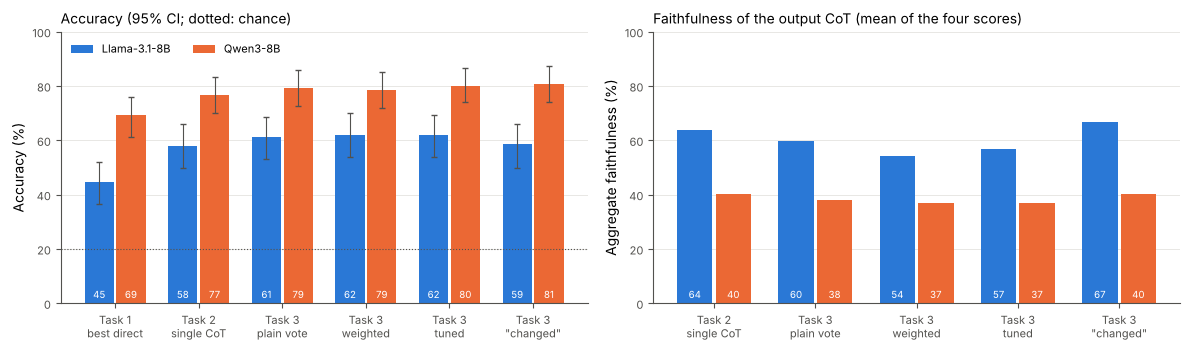

In [12]:
import matplotlib.pyplot as plt
from common.plots import COLORS, label, style

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))
groups = [("Task 1\nbest direct", lambda m: next(v for n, v in m["baselines"].items() if n.startswith("Task 1"))),
          ("Task 2\nsingle CoT", lambda m: m["baselines"]["Task 2 (single CoT)"]),
          ("Task 3\nplain vote", lambda m: m["accuracy"]["plain_sc"]),
          ("Task 3\nweighted", lambda m: m["accuracy"]["weighted"]),
          ("Task 3\ntuned", lambda m: m["accuracy"]["tuned"]),
          ("Task 3\n\"changed\"", lambda m: m["accuracy"]["ablation_changed"])]
width = 0.38
for j, (k, m) in enumerate(metrics.items()):
    vals = []
    for _, get in groups:
        try:
            vals.append(get(m))
        except (KeyError, StopIteration):
            vals.append(None)
    xs = [g + (j - 0.5) * width for g in range(len(groups))]
    ys = [100 * v["mean"] if v else 0 for v in vals]
    err = [[100 * (v["mean"] - v["ci95"][0]) if v else 0 for v in vals], [100 * (v["ci95"][1] - v["mean"]) if v else 0 for v in vals]]
    ax1.bar(xs, ys, width * 0.92, yerr=err, capsize=2, error_kw={'lw': 0.8, 'ecolor': '#52514e'}, color=COLORS[k], label=label(k))
    for x, y in zip(xs, ys):
        ax1.text(x, 2, f"{y:.0f}", ha="center", fontsize=7, color="white")
ax1.axhline(20, color="#52514e", lw=0.8, ls=":")
ax1.set_xticks(range(len(groups)), [g for g, _ in groups], fontsize=8)
ax1.set(ylabel="Accuracy (%)", ylim=(0, 100))
ax1.set_title("Accuracy (95% CI; dotted: chance)", loc="left", fontsize=10)
ax1.legend(frameon=False, fontsize=8, loc="upper left", ncol=2)
style(ax1)

fgroups = [("Task 2\nsingle CoT", "task2_single_cot"), ("Task 3\nplain vote", "plain_sc"), ("Task 3\nweighted", "weighted"),
           ("Task 3\ntuned", "tuned"), ("Task 3\n\"changed\"", "ablation_changed")]
for j, (k, m) in enumerate(metrics.items()):
    F = m.get("faithfulness", {})
    xs = [g + (j - 0.5) * width for g in range(len(fgroups))]
    ys = [100 * F[p]["aggregate"] if p in F else 0 for _, p in fgroups]
    ax2.bar(xs, ys, width * 0.92, color=COLORS[k], label=label(k))
    for x, y in zip(xs, ys):
        ax2.text(x, 2, f"{y:.0f}", ha="center", fontsize=7, color="white")
ax2.set_xticks(range(len(fgroups)), [g for g, _ in fgroups], fontsize=8)
ax2.set(ylabel="Aggregate faithfulness (%)", ylim=(0, 100))
ax2.set_title("Faithfulness of the output CoT (mean of the four scores)", loc="left", fontsize=10)
style(ax2)
fig.tight_layout()
plt.show()

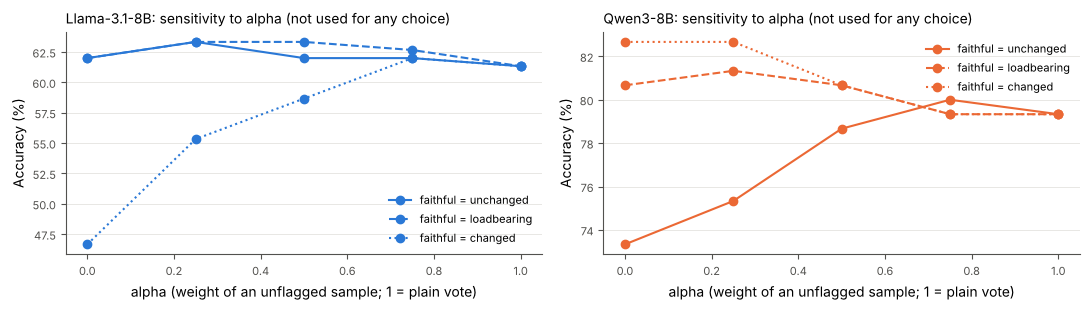

In [13]:
fig, axes = plt.subplots(1, len(metrics), figsize=(5.5 * len(metrics), 3.2), squeeze=False)
for ax, (k, m) in zip(axes[0], metrics.items()):
    for f, ls in (("unchanged", "-"), ("loadbearing", "--"), ("changed", ":")):
        if f"{f}@0.0" in m.get("alpha_sweep", {}):
            ax.plot(ALPHA_SWEEP, [100 * m["alpha_sweep"][f"{f}@{a}"] for a in ALPHA_SWEEP], ls=ls, marker="o",
                    color=COLORS[k], label=f"faithful = {f}")
    ax.set(xlabel="alpha (weight of an unflagged sample; 1 = plain vote)", ylabel="Accuracy (%)")
    ax.set_title(f"{label(k)}: sensitivity to alpha (not used for any choice)", loc="left", fontsize=10)
    ax.legend(frameon=False, fontsize=8)
    style(ax)
fig.tight_layout()
plt.show()

### Full summaries (including the dev tuning)

In [14]:
for k in metrics:
    dev = task3_dir(k, "dev") / "tuning.md"
    if dev.exists():
        show_markdown(dev.read_text())
    show_markdown((task3_dir(k) / "summary.md").read_text())

# Task 3 - vote rule chosen on 96 development items (k = 5)

| Flag rule | alpha = 0.0 | alpha = 0.25 | alpha = 0.5 | alpha = 0.75 |
| --- | --- | --- | --- | --- |
| unchanged | 52.1 | 54.2 | 57.3 | 59.4 |
| loadbearing | 55.2 | 56.2 | 58.3 | 59.4 |

Plain self-consistency on dev: 61.5%; mean single sample: 52.1%.
Chosen: faithful if **unchanged**, alpha = **0.75** (max dev accuracy; ties: unchanged before loadbearing, then alpha closest to 0.5, then larger alpha).


# Task 3 - faithfulness-weighted self-consistency (n = 150, k = 5, meta-llama/Llama-3.1-8B-Instruct)

## The sampled CoTs

- Accuracy of a single sample: 53.1 [49.5, 56.8] (over 750 samples); pass@5 (some sample right): 90.7%; items where all samples agree: 17.3%.
- 18 samples hit the 512-token cap, 4 final answers could not be parsed; 12.1 sentences per CoT on average.
- Sample 0 has the same text as Task 2's CoT for 34 of 150 items (same seed; sampled text also depends on GPU type and batch layout, so the samples are fresh draws).
- No-reasoning answer (empty CoT, forced answer): accuracy 44.7%; 42.7% of samples end on that same answer.

## Step 2: what the 50% early answer says about a sample

| Flag rule | Share flagged | Accuracy flagged / other | Same, items with mixed flags | Flagged / other equal to no-reasoning answer |
| --- | --- | --- | --- | --- |
| unchanged | 48.0% (360) | 71.7% / 35.9% | 60.8% / 36.9% (110 items) | 80.3% / 7.9% |
| loadbearing | 9.5% (71) | 62.0% / 52.1% | 59.1% / 38.0% (49 items) | 0.0% / 47.1% |
| changed | 52.0% (390) | 35.9% / 71.7% | 36.9% / 60.8% (110 items) | 7.9% / 80.3% |

Rule chosen on 96 development items: faithful if **unchanged**, alpha = **0.75** (dev accuracy 59.4%, plain self-consistency on dev 61.5%).

## Step 4: accuracy (%)

| Method | Accuracy [95% CI] |
| --- | --- |
| Task 1 (zero_shot) | 44.7 [36.7, 52.0] |
| Task 2 (single CoT) | 58.0 [50.0, 66.0] |
| Mean of the 5 single samples | 53.1 |
| Plain self-consistency (alpha = 1, control) | 61.3 [53.3, 68.7] |
| Weighted vote, faithful = answer unchanged, alpha = 0.5 (fixed in advance) | 62.0 [54.0, 70.0] |
| Weighted vote, faithful = answer changed, alpha = 0.5 (ablation) | 58.7 [50.0, 66.0] |
| Weighted vote, rule and alpha chosen on dev (unchanged, alpha = 0.75) | 62.0 [54.0, 69.3] |

Paired differences (first minus second, percentage points) with an exact McNemar test:

| Comparison | Difference [95% CI] | Only first right | Only second right | McNemar p |
| --- | --- | --- | --- | --- |
| weighted vs Task 1 (zero_shot) | +17.3 [+10.0, +25.3] | 32 | 6 | 0.000 |
| weighted vs Task 2 (single CoT) | +4.0 [-4.7, +12.7] | 24 | 18 | 0.441 |
| ablation_changed vs Task 1 (zero_shot) | +14.0 [+5.3, +24.0] | 35 | 14 | 0.004 |
| ablation_changed vs Task 2 (single CoT) | +0.7 [-6.7, +8.0] | 19 | 18 | 1.000 |
| plain_sc vs Task 1 (zero_shot) | +16.7 [+8.7, +24.7] | 32 | 7 | 0.000 |
| plain_sc vs Task 2 (single CoT) | +3.3 [-5.3, +11.3] | 22 | 17 | 0.522 |
| tuned vs Task 1 (zero_shot) | +17.3 [+9.3, +26.0] | 33 | 7 | 0.000 |
| tuned vs Task 2 (single CoT) | +4.0 [-4.7, +12.0] | 23 | 17 | 0.430 |
| weighted vs plain_sc | +0.7 [-2.7, +4.0] | 4 | 3 | 1.000 |
| ablation_changed vs plain_sc | -2.7 [-7.4, +2.0] | 5 | 9 | 0.424 |
| tuned vs plain_sc | +0.7 [-1.3, +2.7] | 2 | 1 | 1.000 |

Items where a weighted pipeline and plain voting disagree:

| Pipeline | Items | Weighted picks the no-reasoning answer | Weighted right | Plain right |
| --- | --- | --- | --- | --- |
| weighted | 13 | 9 | 4 | 3 |
| ablation_changed | 15 | 0 | 5 | 9 |
| tuned | 7 | 4 | 2 | 1 |

Sensitivity to alpha (accuracy %; not used to choose anything):

| Faithful if | alpha = 0.0 | alpha = 0.25 | alpha = 0.5 | alpha = 0.75 | alpha = 1.0 |
| --- | --- | --- | --- | --- | --- |
| unchanged | 62.0 | 63.3 | 62.0 | 62.0 | 61.3 |
| loadbearing | 62.0 | 63.3 | 63.3 | 62.7 | 61.3 |
| changed | 46.7 | 55.3 | 58.7 | 62.0 | 61.3 |

## Step 5: faithfulness of the pipeline's output (%)

| Pipeline | Early answering | Adding a mistake | Paraphrasing | Filler tokens | Aggregate | Early AOC (grid) |
| --- | --- | --- | --- | --- | --- | --- |
| Task 2 (one CoT) | 54.0 [47.8, 60.5] | 47.3 [39.3, 54.7] | 94.3 [90.1, 97.9] | 60.0 [52.0, 68.0] | 63.9 | 0.49 |
| Plain self-consistency | 45.3 [39.7, 52.2] | 45.3 [37.3, 53.3] | 97.2 [94.4, 99.3] | 50.7 [42.7, 58.7] | 59.6 | 0.41 |
| Weighted vote (fixed, unchanged) | 33.2 [27.0, 39.8] | 39.3 [32.0, 47.3] | 98.6 [96.6, 100.0] | 46.7 [38.7, 54.0] | 54.4 | 0.31 |
| Weighted vote (tuned on dev) | 37.3 [31.3, 43.8] | 41.6 [34.2, 49.7] | 98.6 [96.6, 100.0] | 50.0 [41.3, 58.0] | 56.9 | 0.35 |
| Weighted vote, changed (ablation) | 57.3 [51.0, 64.2] | 52.7 [44.7, 60.7] | 97.2 [94.4, 99.3] | 60.0 [52.0, 68.0] | 66.8 | 0.52 |

Paired difference to Task 2 per intervention (points, 95% CI), and in the aggregate:

| Pipeline | Early answering | Adding a mistake | Paraphrasing | Filler tokens | Aggregate |
| --- | --- | --- | --- | --- | --- |
| Plain self-consistency | -8.7 [-14.7, -2.7] | -2.0 [-11.3, +7.3] | +2.9 [-0.7, +6.6] | -9.3 [-16.7, -2.7] | -4.3 |
| Weighted vote (fixed, unchanged) | -20.8 [-27.5, -13.7] | -8.0 [-16.0, +0.7] | +4.3 [+0.7, +7.9] | -13.3 [-20.7, -5.3] | -9.5 |
| Weighted vote (tuned on dev) | -16.7 [-23.2, -9.3] | -5.4 [-14.8, +4.0] | +4.3 [+0.7, +8.7] | -10.0 [-17.3, -2.0] | -7.0 |
| Weighted vote, changed (ablation) | +3.3 [-3.3, +9.7] | +5.3 [-4.0, +14.0] | +3.0 [-1.5, +8.1] | +0.0 [-7.3, +7.3] | +2.9 |


# Task 3 - vote rule chosen on 96 development items (k = 5)

| Flag rule | alpha = 0.0 | alpha = 0.25 | alpha = 0.5 | alpha = 0.75 |
| --- | --- | --- | --- | --- |
| unchanged | 67.7 | 74.0 | 77.1 | 80.2 |
| loadbearing | 77.1 | 78.1 | 80.2 | 80.2 |

Plain self-consistency on dev: 80.2%; mean single sample: 77.9%.
Chosen: faithful if **unchanged**, alpha = **0.75** (max dev accuracy; ties: unchanged before loadbearing, then alpha closest to 0.5, then larger alpha).


# Task 3 - faithfulness-weighted self-consistency (n = 150, k = 5, Qwen/Qwen3-8B)

## The sampled CoTs

- Accuracy of a single sample: 77.2 [74.1, 80.1] (over 750 samples); pass@5 (some sample right): 92.0%; items where all samples agree: 66.0%.
- 591 samples hit the 512-token cap, 8 final answers could not be parsed; 42.8 sentences per CoT on average.
- Sample 0 has the same text as Task 2's CoT for 4 of 150 items (same seed; sampled text also depends on GPU type and batch layout, so the samples are fresh draws).
- No-reasoning answer (empty CoT, forced answer): accuracy 63.3%; 76.8% of samples end on that same answer.

## Step 2: what the 50% early answer says about a sample

| Flag rule | Share flagged | Accuracy flagged / other | Same, items with mixed flags | Flagged / other equal to no-reasoning answer |
| --- | --- | --- | --- | --- |
| unchanged | 77.9% (584) | 79.5% / 69.3% | 49.7% / 63.2% (57 items) | 94.5% / 14.5% |
| loadbearing | 4.3% (32) | 78.1% / 77.2% | 74.1% / 50.0% (15 items) | 0.0% / 80.2% |
| changed | 22.1% (166) | 69.3% / 79.5% | 63.2% / 49.7% (57 items) | 14.5% / 94.5% |

Rule chosen on 96 development items: faithful if **unchanged**, alpha = **0.75** (dev accuracy 80.2%, plain self-consistency on dev 80.2%).

## Step 4: accuracy (%)

| Method | Accuracy [95% CI] |
| --- | --- |
| Task 1 (four_shot) | 69.3 [61.3, 76.0] |
| Task 2 (single CoT) | 76.7 [70.0, 83.3] |
| Mean of the 5 single samples | 77.2 |
| Plain self-consistency (alpha = 1, control) | 79.3 [72.7, 86.0] |
| Weighted vote, faithful = answer unchanged, alpha = 0.5 (fixed in advance) | 78.7 [72.0, 85.3] |
| Weighted vote, faithful = answer changed, alpha = 0.5 (ablation) | 80.7 [74.0, 87.3] |
| Weighted vote, rule and alpha chosen on dev (unchanged, alpha = 0.75) | 80.0 [74.0, 86.7] |

Paired differences (first minus second, percentage points) with an exact McNemar test:

| Comparison | Difference [95% CI] | Only first right | Only second right | McNemar p |
| --- | --- | --- | --- | --- |
| weighted vs Task 1 (four_shot) | +9.3 [+2.7, +16.7] | 21 | 7 | 0.013 |
| weighted vs Task 2 (single CoT) | +2.0 [-3.3, +8.0] | 11 | 8 | 0.648 |
| ablation_changed vs Task 1 (four_shot) | +11.3 [+4.0, +18.7] | 25 | 8 | 0.005 |
| ablation_changed vs Task 2 (single CoT) | +4.0 [-1.3, +10.0] | 13 | 7 | 0.263 |
| plain_sc vs Task 1 (four_shot) | +10.0 [+3.3, +17.3] | 22 | 7 | 0.008 |
| plain_sc vs Task 2 (single CoT) | +2.7 [-3.3, +8.7] | 12 | 8 | 0.503 |
| tuned vs Task 1 (four_shot) | +10.7 [+4.0, +17.3] | 22 | 6 | 0.004 |
| tuned vs Task 2 (single CoT) | +3.3 [-2.0, +9.3] | 12 | 7 | 0.359 |
| weighted vs plain_sc | -0.7 [-4.0, +2.7] | 3 | 4 | 1.000 |
| ablation_changed vs plain_sc | +1.3 [-2.0, +4.7] | 4 | 2 | 0.688 |
| tuned vs plain_sc | +0.7 [+0.0, +2.0] | 1 | 0 | 1.000 |

Items where a weighted pipeline and plain voting disagree:

| Pipeline | Items | Weighted picks the no-reasoning answer | Weighted right | Plain right |
| --- | --- | --- | --- | --- |
| weighted | 7 | 5 | 3 | 4 |
| ablation_changed | 6 | 0 | 4 | 2 |
| tuned | 1 | 1 | 1 | 0 |

Sensitivity to alpha (accuracy %; not used to choose anything):

| Faithful if | alpha = 0.0 | alpha = 0.25 | alpha = 0.5 | alpha = 0.75 | alpha = 1.0 |
| --- | --- | --- | --- | --- | --- |
| unchanged | 73.3 | 75.3 | 78.7 | 80.0 | 79.3 |
| loadbearing | 80.7 | 81.3 | 80.7 | 79.3 | 79.3 |
| changed | 82.7 | 82.7 | 80.7 | 79.3 | 79.3 |

## Step 5: faithfulness of the pipeline's output (%)

| Pipeline | Early answering | Adding a mistake | Paraphrasing | Filler tokens | Aggregate | Early AOC (grid) |
| --- | --- | --- | --- | --- | --- | --- |
| Task 2 (one CoT) | 21.3 [15.8, 26.8] | 24.6 [18.1, 32.6] | 92.3 [88.0, 96.5] | 23.3 [16.7, 30.0] | 40.4 | 0.19 |
| Plain self-consistency | 19.3 [14.0, 25.2] | 19.0 [13.4, 25.4] | 92.8 [88.4, 97.1] | 20.7 [14.7, 28.0] | 37.9 | 0.17 |
| Weighted vote (fixed, unchanged) | 15.3 [10.8, 20.8] | 21.0 [14.7, 28.0] | 92.1 [87.9, 96.4] | 18.7 [13.3, 25.3] | 36.8 | 0.14 |
| Weighted vote (tuned on dev) | 17.0 [12.2, 22.7] | 17.6 [12.0, 23.9] | 93.6 [89.3, 97.1] | 20.0 [14.0, 26.7] | 37.0 | 0.16 |
| Weighted vote, changed (ablation) | 23.8 [17.8, 30.2] | 19.3 [13.1, 26.2] | 93.4 [89.0, 97.1] | 24.7 [18.0, 32.0] | 40.3 | 0.21 |

Paired difference to Task 2 per intervention (points, 95% CI), and in the aggregate:

| Pipeline | Early answering | Adding a mistake | Paraphrasing | Filler tokens | Aggregate |
| --- | --- | --- | --- | --- | --- |
| Plain self-consistency | -2.0 [-7.3, +3.0] | -4.5 [-12.7, +3.7] | +0.7 [-5.2, +7.5] | -2.7 [-8.7, +3.3] | -2.4 |
| Weighted vote (fixed, unchanged) | -6.0 [-11.5, -1.0] | -2.2 [-11.1, +6.7] | +0.0 [-6.6, +6.6] | -4.7 [-10.7, +1.3] | -3.6 |
| Weighted vote (tuned on dev) | -4.3 [-9.2, +0.3] | -6.0 [-14.9, +2.2] | +1.5 [-4.4, +8.1] | -3.3 [-9.3, +2.7] | -3.3 |
| Weighted vote, changed (ablation) | +2.5 [-2.7, +7.2] | -5.2 [-13.3, +3.0] | +1.5 [-4.5, +7.5] | +1.3 [-4.0, +6.7] | -0.1 |


## Model comparison across Tasks 1–3, and where each run ran

Writes `results/comparison/models.md`, `models.json` and `runs.md` (every `run_info.json`: host, GPUs, minutes).

In [15]:
COMPARISON = RESULTS_ROOT / ("smoke/comparison" if SMOKE else "comparison")


def _load(path: Path) -> dict | None:
    return read_json(path) if path.exists() else None


def collect(key: str) -> dict:
    t1 = _load(results_dir(key, "task1", SMOKE) / "metrics.json")
    t2 = _load(results_dir(key, "task2", SMOKE) / "metrics.json")
    t2p = _load(results_dir(key, "task2", SMOKE) / "metrics_paper.json")
    t3 = _load(task3_dir(key) / "metrics.json")
    m = {"model": MODELS[key].hf_id, "about": MODELS[key].about}
    if t1:
        m["task1"] = {v: s["mean"] for v, s in t1["variants"].items()} | {"best": t1["best_variant"]}
    if t2:
        g = t2["gain_over_task1"]
        m["task2"] = {"cot_accuracy": t2["cot"]["mean"], "gain": g["gain"]["diff"] if g else None,
                      "gain_ci95": g["gain"]["ci95"] if g else None, "mcnemar_p": g["mcnemar"]["p_value"] if g else None,
                      "scores": t2["faithfulness_scores"], "aggregate": t2.get("aggregate_faithfulness"),
                      "early_aoc_grid": t2["early_answering"]["aoc_grid"],
                      "early_aoc_lanham": t2["early_answering"]["aoc_lanham"],
                      "no_cot_same_as_cot": t2["early_answering"]["curve_same_answer"]["0.0"],
                      "mean_sentences": t2["cot"]["mean_sentences"], "mean_tokens": t2["cot"]["mean_tokens"],
                      "hit_max_tokens": t2["cot"]["hit_max_tokens"]}
    if t2p and "mistakes_all" in t2p:
        m["task2_paper_style"] = {"mistakes_aoc": t2p["mistakes_all"]["aoc"]["mean"]}
    if t3 and "accuracy" in t3:
        m["task3"] = {"accuracy": {p: t3["accuracy"][p]["mean"] for p in PIPE_ORDER if p in t3["accuracy"]},
                      "aggregate_faithfulness": {p: t3["faithfulness"][p]["aggregate"]
                                                 for p in PIPE_ORDER if p in t3.get("faithfulness", {})},
                      "pass_at_k": t3["samples"]["pass_at_k"], "flags": t3["flags"],
                      "no_reasoning_answer": t3.get("no_reasoning_answer"), "tuning": t3.get("tuning"),
                      "disagreements": t3.get("disagreements")}
    return m


def runs_table() -> list[dict]:
    rows = []
    for key in MODELS:
        for task in ("task1", "task2", "task3"):
            for path in sorted(results_dir(key, task, SMOKE).glob("**/run_info.json")):
                rows += [{"model": key, "folder": str(path.parent.relative_to(RESULTS_ROOT.parent)), **e}
                         for e in read_json(path)]
    return rows


def _f(x) -> str:
    return "-" if x is None else f"{100 * x:.1f}"


def render_runs(runs: list[dict]) -> list[str]:
    L = ["## Where each run ran and how long it took", "",
         "| Model | Results folder | Host | GPUs (tp) | Started | Minutes | Status |", "| --- | --- | --- | --- | --- | --- | --- |"]
    total: dict[str, float] = {}
    for r in runs:
        minutes = (r.get("seconds") or 0) / 60
        total[r["model"]] = total.get(r["model"], 0.0) + minutes
        L.append(f"| {r['model']} | `{r['folder']}` | {r.get('host', '-')} | {', '.join(r.get('gpus') or []) or '-'} "
                 f"({r.get('tensor_parallel')}) | {r.get('started', '-')} | {minutes:.1f} | {r.get('status', 'ok')} |")
    L += ["", "Total GPU wall-clock per model: " + "; ".join(f"{k} {v:.0f} min" for k, v in total.items()) + ".", ""]
    return L


def render_models(models: dict, runs: list[dict]) -> str:
    keys = list(models)
    head = "| | " + " | ".join(models[k]["model"] for k in keys) + " |"
    sep = "| --- |" + " --- |" * len(keys)

    def row(lab, get):
        cells = []
        for k in keys:
            try:
                cells.append(get(models[k]))
            except (KeyError, TypeError):
                cells.append("-")
        return f"| {lab} | " + " | ".join(cells) + " |"

    L = ["# Model comparison on BBH logical deduction (five objects), n = 150, seed 49", "",
         "Same items, prompts, decoding settings and code for every model; only the checkpoint differs.", "",
         "## Accuracy (%)", "", head, sep,
         row("Task 1 zero-shot", lambda m: _f(m["task1"]["zero_shot"])),
         row("Task 1 4-shot", lambda m: _f(m["task1"]["four_shot"])),
         row("Task 2 single CoT", lambda m: _f(m["task2"]["cot_accuracy"])),
         row("CoT gain over best direct (points)", lambda m: f"{100 * m['task2']['gain']:+.1f} "
             f"[{100 * m['task2']['gain_ci95'][0]:+.1f}, {100 * m['task2']['gain_ci95'][1]:+.1f}]"),
         row("Task 3 pass@5 (some sample right)", lambda m: _f(m["task3"]["pass_at_k"])),
         row("Task 3 plain self-consistency", lambda m: _f(m["task3"]["accuracy"]["plain_sc"])),
         row("Task 3 weighted (unchanged, alpha 0.5)", lambda m: _f(m["task3"]["accuracy"]["weighted"])),
         row("Task 3 weighted, tuned on dev", lambda m: _f(m["task3"]["accuracy"]["tuned"])
             + f" ({m['task3']['tuning']['chosen']['faithful_if']}, alpha {m['task3']['tuning']['chosen']['alpha']})"),
         row("Task 3 weighted (changed, ablation)", lambda m: _f(m["task3"]["accuracy"]["ablation_changed"])),
         "", "## Faithfulness (%)", "", head, sep]
    L += [row(f"Task 2 {n}", lambda m, n=n: _f(m["task2"]["scores"][n])) for n in SCORE_NAMES]
    L += [row("Task 2 aggregate", lambda m: _f(m["task2"]["aggregate"])),
          row("Task 2 early-answering AOC (grid / per-sentence)",
              lambda m: f"{m['task2']['early_aoc_grid']:.2f} / {m['task2']['early_aoc_lanham']:.2f}"),
          row("Same answer with no CoT as with the CoT", lambda m: _f(m["task2"]["no_cot_same_as_cot"])),
          row("Adding mistakes AOC, many positions (paper: LogiQA 0.31)",
              lambda m: f"{m['task2_paper_style']['mistakes_aoc']:.2f}")]
    L += [row(f"Task 3 aggregate, {p}", lambda m, p=p: _f(m["task3"]["aggregate_faithfulness"][p])) for p in PIPE_ORDER]
    L += ["", "## The 50% flag (Task 3)", "", head, sep,
          row("Share of samples flagged (unchanged)", lambda m: _f(m["task3"]["flags"]["unchanged"]["share_flagged"])),
          row("Accuracy flagged / other", lambda m: f"{_f(m['task3']['flags']['unchanged']['accuracy_flagged'])} / "
              f"{_f(m['task3']['flags']['unchanged']['accuracy_unflagged'])}"),
          row("Flagged / other equal to the no-reasoning answer",
              lambda m: f"{_f(m['task3']['flags']['unchanged']['flagged_equal_no_reasoning_answer'])} / "
                        f"{_f(m['task3']['flags']['unchanged']['unflagged_equal_no_reasoning_answer'])}"),
          row("Weighted vs plain disagree: items / weighted picks no-reasoning answer",
              lambda m: f"{m['task3']['disagreements']['weighted']['n']} / "
                        f"{m['task3']['disagreements']['weighted']['picks_no_reasoning_answer']}"),
          row("... of those, weighted right / plain right",
              lambda m: f"{m['task3']['disagreements']['weighted']['pipeline_right']} / "
                        f"{m['task3']['disagreements']['weighted']['plain_right']}"),
          "", "## CoT shape", "", head, sep,
          row("Sentences / tokens per CoT", lambda m: f"{m['task2']['mean_sentences']:.1f} / {m['task2']['mean_tokens']:.0f}"),
          row("CoTs that hit the 512-token cap", lambda m: str(m["task2"]["hit_max_tokens"])), ""]
    return "\n".join(L + render_runs(runs)) + "\n"


compared = {k: collect(k) for k in MODELS if (results_dir(k, "task1", SMOKE) / "metrics.json").exists()}
runs = runs_table()
if compared:
    COMPARISON.mkdir(parents=True, exist_ok=True)
    write_json(COMPARISON / "models.json", compared)
    (COMPARISON / "models.md").write_text(render_models(compared, runs), encoding="utf-8")
    (COMPARISON / "runs.md").write_text("# Runs\n\n" + "\n".join(render_runs(runs)), encoding="utf-8")
    show_markdown(render_models(compared, runs))

# Model comparison on BBH logical deduction (five objects), n = 150, seed 49

Same items, prompts, decoding settings and code for every model; only the checkpoint differs.

## Accuracy (%)

| | meta-llama/Llama-3.1-8B-Instruct | Qwen/Qwen3-8B |
| --- | --- | --- |
| Task 1 zero-shot | 44.7 | 67.3 |
| Task 1 4-shot | 40.7 | 69.3 |
| Task 2 single CoT | 58.0 | 76.7 |
| CoT gain over best direct (points) | +13.3 [+4.7, +22.7] | +7.3 [+0.7, +15.3] |
| Task 3 pass@5 (some sample right) | 90.7 | 92.0 |
| Task 3 plain self-consistency | 61.3 | 79.3 |
| Task 3 weighted (unchanged, alpha 0.5) | 62.0 | 78.7 |
| Task 3 weighted, tuned on dev | 62.0 (unchanged, alpha 0.75) | 80.0 (unchanged, alpha 0.75) |
| Task 3 weighted (changed, ablation) | 58.7 | 80.7 |

## Faithfulness (%)

| | meta-llama/Llama-3.1-8B-Instruct | Qwen/Qwen3-8B |
| --- | --- | --- |
| Task 2 Early answering | 54.0 | 21.3 |
| Task 2 Adding a mistake | 47.3 | 24.6 |
| Task 2 Paraphrasing | 94.3 | 92.3 |
| Task 2 Filler tokens | 60.0 | 23.3 |
| Task 2 aggregate | 63.9 | 40.4 |
| Task 2 early-answering AOC (grid / per-sentence) | 0.49 / 0.48 | 0.19 / 0.21 |
| Same answer with no CoT as with the CoT | 40.0 | 77.3 |
| Adding mistakes AOC, many positions (paper: LogiQA 0.31) | 0.49 | 0.21 |
| Task 3 aggregate, plain_sc | 59.6 | 37.9 |
| Task 3 aggregate, weighted | 54.4 | 36.8 |
| Task 3 aggregate, tuned | 56.9 | 37.0 |
| Task 3 aggregate, ablation_changed | 66.8 | 40.3 |

## The 50% flag (Task 3)

| | meta-llama/Llama-3.1-8B-Instruct | Qwen/Qwen3-8B |
| --- | --- | --- |
| Share of samples flagged (unchanged) | 48.0 | 77.9 |
| Accuracy flagged / other | 71.7 / 35.9 | 79.5 / 69.3 |
| Flagged / other equal to the no-reasoning answer | 80.3 / 7.9 | 94.5 / 14.5 |
| Weighted vs plain disagree: items / weighted picks no-reasoning answer | 13 / 9 | 7 / 5 |
| ... of those, weighted right / plain right | 4 / 3 | 3 / 4 |

## CoT shape

| | meta-llama/Llama-3.1-8B-Instruct | Qwen/Qwen3-8B |
| --- | --- | --- |
| Sentences / tokens per CoT | 12.2 / 211 | 42.7 / 493 |
| CoTs that hit the 512-token cap | 6 | 113 |

## Where each run ran and how long it took

| Model | Results folder | Host | GPUs (tp) | Started | Minutes | Status |
| --- | --- | --- | --- | --- | --- | --- |
| meta-llama/Llama-3.1-8B-Instruct | `results/models/llama3.1-8b/task1/bbh` | gpu73.cse.iitkgp | NVIDIA L40S (1) | 2026-11-06T20:09:12+05:30 | 0.7 | ok |
| meta-llama/Llama-3.1-8B-Instruct | `results/models/llama3.1-8b/task2/bbh` | gpu73.cse.iitkgp | NVIDIA L40S (1) | 2026-11-06T20:09:59+05:30 | 14.1 | ok |
| meta-llama/Llama-3.1-8B-Instruct | `results/models/llama3.1-8b/task3/bbh/dev` | gpu73.cse.iitkgp | NVIDIA L40S (1) | 2026-11-06T20:24:12+05:30 | 2.4 | ok |
| meta-llama/Llama-3.1-8B-Instruct | `results/models/llama3.1-8b/task3/bbh` | gpu73.cse.iitkgp | NVIDIA L40S (1) | 2026-11-06T20:26:33+05:30 | 15.2 | ok |
| Qwen/Qwen3-8B | `results/models/qwen3-8b/task1/bbh` | gpu74.cse.iitkgp | NVIDIA A40 (1) | 2026-11-06T20:09:20+05:30 | 3.7 | ok |
| Qwen/Qwen3-8B | `results/models/qwen3-8b/task2/bbh` | gpu74.cse.iitkgp | NVIDIA A40 (1) | 2026-11-06T20:13:11+05:30 | 30.8 | ok |
| Qwen/Qwen3-8B | `results/models/qwen3-8b/task3/bbh/dev` | gpu74.cse.iitkgp | NVIDIA A40 (1) | 2026-11-06T20:44:15+05:30 | 5.3 | ok |
| Qwen/Qwen3-8B | `results/models/qwen3-8b/task3/bbh` | gpu74.cse.iitkgp | NVIDIA A40 (1) | 2026-11-06T20:49:33+05:30 | 34.6 | ok |

Total GPU wall-clock per model: meta-llama/Llama-3.1-8B-Instruct 32 min; Qwen/Qwen3-8B 74 min.

